<a href="https://colab.research.google.com/github/hyo-yeon-lee/MCNB-Probability-and-Statistics/blob/main/lecture03_permutation_chi2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Observed Difference: 8.60
P-value: 0.008


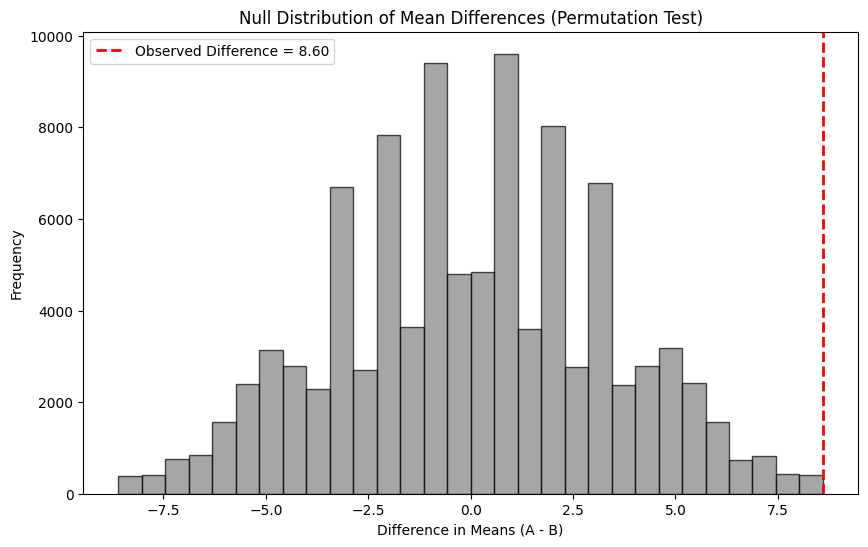

Reject the null hypothesis: Significant difference between groups.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Sample fMRI data
fmri_data_A = [103, 99, 98, 101, 99]
fmri_data_B = [90, 87, 96, 93, 91]

# Observed difference in means
observed_diff = np.mean(fmri_data_A) - np.mean(fmri_data_B)
print(f"Observed Difference: {observed_diff:.2f}")

# Combine data
combined_data = np.array(fmri_data_A + fmri_data_B)
n_permutations = 100000
perm_diffs = []

# Permutation test
for _ in range(n_permutations):
    np.random.shuffle(combined_data)
    perm_A = combined_data[:len(fmri_data_A)]
    perm_B = combined_data[len(fmri_data_A):]
    perm_diff = np.mean(perm_A) - np.mean(perm_B)
    perm_diffs.append(perm_diff)

# Convert permutation differences to a numpy array for easier plotting
perm_diffs = np.array(perm_diffs)

# Calculate p-value (two-tailed)
p_value = np.mean(np.abs(perm_diffs) >= np.abs(observed_diff))
print(f"P-value: {p_value:.3f}")

# Plot the null distribution of permuted differences
plt.figure(figsize=(10, 6))
plt.hist(perm_diffs, bins=30, color='grey', edgecolor='black', alpha=0.7)
plt.axvline(observed_diff, color='red', linestyle='dashed', linewidth=2, label=f'Observed Difference = {observed_diff:.2f}')
plt.xlabel("Difference in Means (A - B)")
plt.ylabel("Frequency")
plt.title("Null Distribution of Mean Differences (Permutation Test)")
plt.legend()
plt.show()

# Conclusion
alpha = 0.05
if p_value < alpha:
    print("Reject the null hypothesis: Significant difference between groups.")
else:
    print("Fail to reject the null hypothesis: No significant difference between groups.")


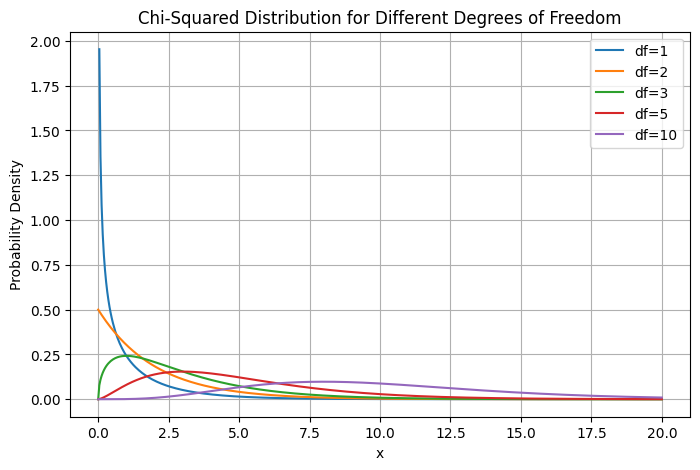

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2

# Set up the figure
plt.figure(figsize=(8, 5))

# Define the degrees of freedom
degrees_of_freedom = [1, 2, 3, 5, 10]

# Generate values for the x-axis (0 to 20)
x = np.linspace(0, 20, 500)

# Plot the chi-squared distribution for each degree of freedom
for df in degrees_of_freedom:
    plt.plot(x, chi2.pdf(x, df), label=f'df={df}')

# Add labels and title
plt.title('Chi-Squared Distribution for Different Degrees of Freedom')
plt.xlabel('x')
plt.ylabel('Probability Density')
plt.legend()

# Show the plot
plt.grid(True)
plt.show()


Observed frequencies: [1 0 1 2 2 4]
Expected frequencies for each face: [1.66666667 1.66666667 1.66666667 1.66666667 1.66666667 1.66666667]
Observed: 1, Expected: 1.6666666666666667
Observed: 0, Expected: 1.6666666666666667
Observed: 1, Expected: 1.6666666666666667
Observed: 2, Expected: 1.6666666666666667
Observed: 2, Expected: 1.6666666666666667
Observed: 4, Expected: 1.6666666666666667
Chi-square statistic: 5.599999999999999


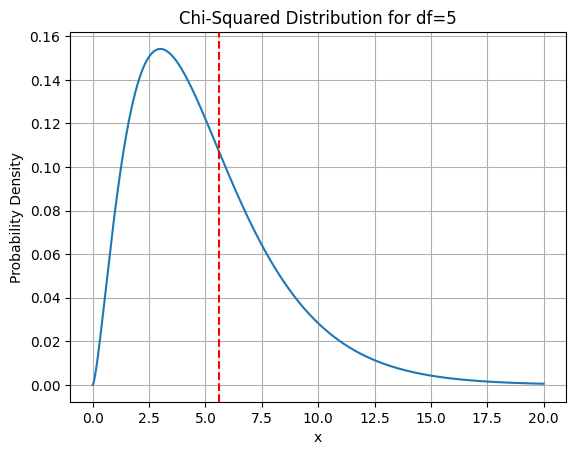

P-value: 0.34710506828171583
Fail to reject the null hypothesis: The die is fair.


In [ ]:
import numpy as np
from scipy.stats import chisquare
import matplotlib.pyplot as plt
from scipy.stats import chi2

observed_rolls = [1, 3, 4, 4, 5, 5, 6, 6, 6, 6]

# Count the frequency of each die face (1 to 6)
observed_counts = np.array([observed_rolls.count(i) for i in range(1, 7)])
print("Observed frequencies:", observed_counts)

# We expect each face to occur equally, so for 10 rolls, each face should occur 10 / 6 times on average.
n_rolls = len(observed_rolls)
n_sides = 6
expected_frequency = n_rolls / n_sides  # Expected frequency for each die face
expected_frequencies = np.array([expected_frequency] * n_sides)
print("Expected frequencies for each face:", expected_frequencies)

# Explicitly compute Chi2
chi2_statistic = 0
for i in range(6):
    print(f"Observed: {observed_counts[i]}, Expected: {expected_frequencies[i]}")
    chi2_statistic += ((observed_counts[i] - expected_frequencies[i]) ** 2) / expected_frequencies[i]
print(f"Chi-square statistic: {chi2_statistic}")

# Faster more elegant way using broadcasting and the axis= argument
# chi2_statistic = np.sum(((observed_counts - expected_frequencies) ** 2) / expected_frequencies)
# print(f"Chi-square statistic: {chi2_statistic}")

# plot chi2_statistic with the distribution for df=5
plt.figure()
pdf = chi2.pdf(np.linspace(0, 20, 1000), df=5)
plt.plot(np.linspace(0, 20, 1000), pdf)
plt.axvline(x=chi2_statistic, color='r', linestyle='--')
plt.title('Chi-Squared Distribution for df=5')
plt.xlabel('x')
plt.ylabel('Probability Density')
plt.grid(True)
plt.show()

# Get p-value
p_value = 1 - chi2.cdf(chi2_statistic, df=5)
print(f"P-value: {p_value}")

# Conclusion based on the p-value
alpha = 0.05  # Significance level
if p_value < alpha:
    print("Reject the null hypothesis: The die is not fair.")
else:
    print("Fail to reject the null hypothesis: The die is fair.")


In [ ]:
import numpy as np
from scipy.stats import chisquare

# Step 1: Observed results from 10 dice rolls
observed_rolls = [1, 3, 4, 4, 5, 5, 6, 6, 6, 6]

# Count the frequency of each die face (1 to 6)
observed_counts = np.array([observed_rolls.count(i) for i in range(1, 7)])

# Display observed frequencies
print("Observed frequencies:", observed_counts)

# Step 2: Define expected frequencies (for a fair die)
# We expect each face to occur equally, so for 10 rolls, each face should occur 10 / 6 times on average.
n_rolls = len(observed_rolls)
n_sides = 6
expected_frequency = n_rolls / n_sides  # Expected frequency for each die face
expected_frequencies = np.array([expected_frequency] * n_sides)

# Display expected frequencies
print("Expected frequencies for each face:", expected_frequencies)

# Step 3: Perform the chi-square goodness of fit test
# We'll use scipy's `chisquare` function
chi2_statistic, p_value = chisquare(observed_counts, f_exp=expected_frequencies)

# Display the chi-square statistic and p-value
print(f"Chi-square statistic: {chi2_statistic}")
print(f"P-value: {p_value}")

# Step 4: Conclusion based on the p-value
alpha = 0.05  # Significance level
if p_value < alpha:
    print("Reject the null hypothesis: The die is not fair.")
else:
    print("Fail to reject the null hypothesis: The die is fair.")


Observed frequencies: [1 0 1 2 2 4]
Expected frequencies for each face: [1.66666667 1.66666667 1.66666667 1.66666667 1.66666667 1.66666667]
Chi-square statistic: 5.599999999999999
P-value: 0.3471050682817159
Fail to reject the null hypothesis: The die is fair.
